Siap: colorization_deploy_v2.prototxt
Siap: colorization_release_v2.caffemodel
Siap: pts_in_hull.npy

Informasi gambar
Nama       : poto_saya.jpeg
Lebar      : 720 piksel
Tinggi     : 1280 piksel
Total piksel: 921600

Model AI berhasil dimuat.
Gambar grayscale disimpan: C:\Users\Asus Vivobook\Downloads\tugas-citra digital\hasil\motor_grayscale.png
Hasil pewarnaan disimpan : C:\Users\Asus Vivobook\Downloads\tugas-citra digital\hasil\motor_colorization.png


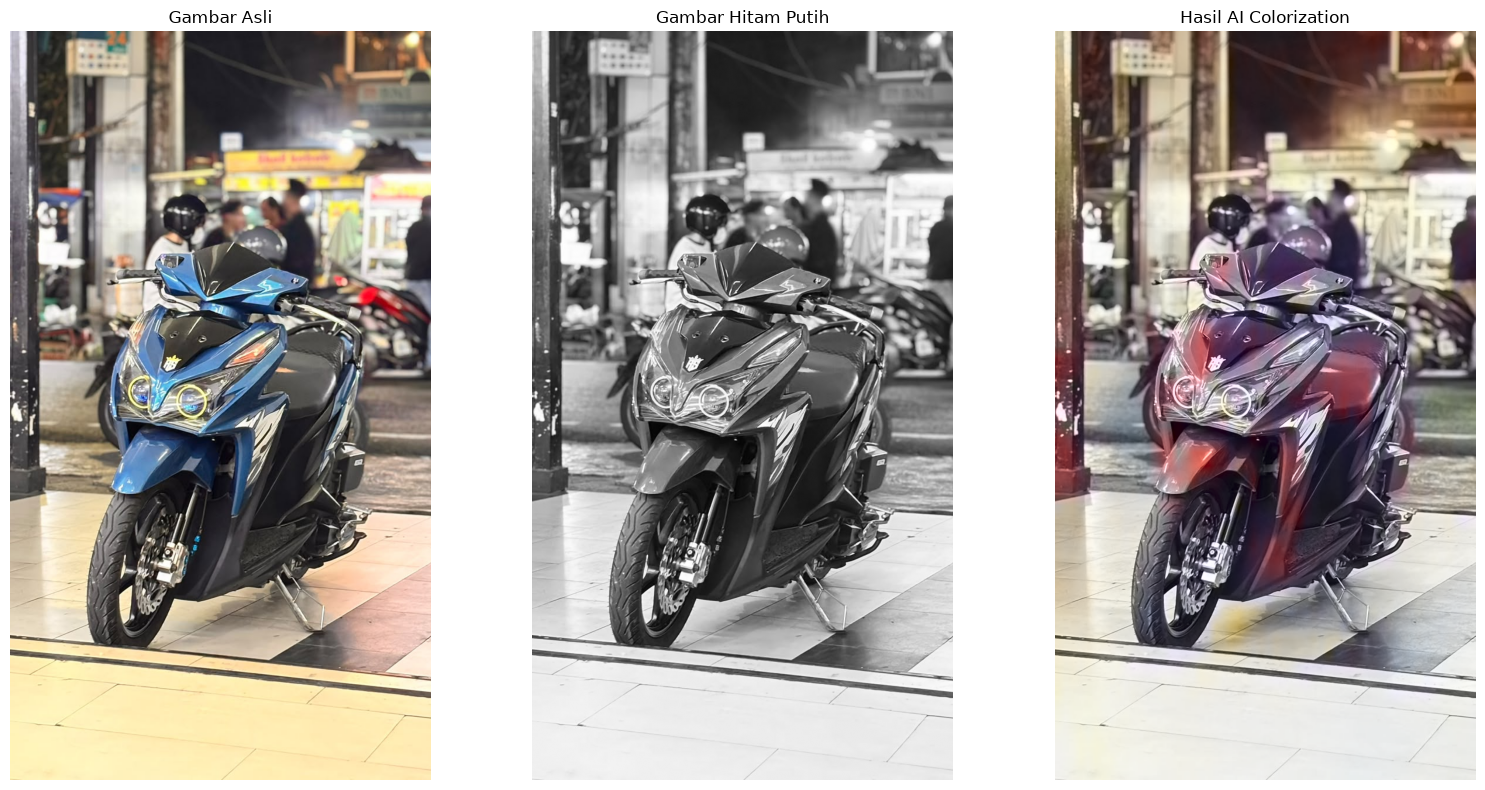


Proses selesai!
Semua hasil berada di folder: C:\Users\Asus Vivobook\Downloads\tugas-citra digital\hasil


In [1]:

import os
import urllib.request
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# ==========================================
# 1. PENGATURAN FOLDER
# ==========================================

BASE_DIR = Path.cwd().resolve()
FOLDER_GAMBAR = BASE_DIR / "gambar"
FOLDER_MODEL = BASE_DIR / "model"
FOLDER_HASIL = BASE_DIR / "hasil"

FOLDER_GAMBAR.mkdir(exist_ok=True)
FOLDER_MODEL.mkdir(exist_ok=True)
FOLDER_HASIL.mkdir(exist_ok=True)

FILE_GAMBAR = FOLDER_GAMBAR / "poto_saya.jpeg"

PROTO = FOLDER_MODEL / "colorization_deploy_v2.prototxt"
MODEL = FOLDER_MODEL / "colorization_release_v2.caffemodel"
POINTS = FOLDER_MODEL / "pts_in_hull.npy"

URLS = {
    PROTO: (
        "https://raw.githubusercontent.com/"
        "richzhang/colorization/caffe/colorization/"
        "models/colorization_deploy_v2.prototxt"
    ),
    MODEL: (
        "https://storage.openvinotoolkit.org/"
        "repositories/datumaro/models/colorization/"
        "colorization_release_v2.caffemodel"
    ),
    POINTS: (
        "https://raw.githubusercontent.com/"
        "richzhang/colorization/caffe/colorization/"
        "resources/pts_in_hull.npy"
    )
}

# ==========================================
# 2. DOWNLOAD MODEL JIKA BELUM ADA
# ==========================================

for lokasi, url in URLS.items():
    if not lokasi.exists():
        print(f"Mengunduh {lokasi.name} ...")
        try:
            urllib.request.urlretrieve(url, lokasi)
        except Exception as error:
            raise RuntimeError(
                f"Gagal mengunduh {lokasi.name}. "
                "Periksa koneksi internet dan coba lagi."
            ) from error

    if lokasi.stat().st_size == 0:
        raise RuntimeError(f"File model kosong: {lokasi.name}")

    print(f"Siap: {lokasi.name}")

# ==========================================
# 3. MEMBACA GAMBAR
# ==========================================

if not FILE_GAMBAR.exists():
    raise FileNotFoundError(
        f"Gambar tidak ditemukan: {FILE_GAMBAR}\n"
        "Simpan foto motor dengan nama motor.jpeg "
        "di dalam folder gambar."
    )

gambar_bgr = cv2.imread(str(FILE_GAMBAR))

if gambar_bgr is None:
    raise ValueError("Gambar gagal dibaca. Periksa format file.")

gambar_rgb = cv2.cvtColor(
    gambar_bgr, cv2.COLOR_BGR2RGB
)

tinggi, lebar = gambar_rgb.shape[:2]

print("\nInformasi gambar")
print("Nama       :", FILE_GAMBAR.name)
print("Lebar      :", lebar, "piksel")
print("Tinggi     :", tinggi, "piksel")
print("Total piksel:", tinggi * lebar)

# ==========================================
# 4. MEMUAT MODEL DEEP LEARNING
# ==========================================

net = cv2.dnn.readNetFromCaffe(
    str(PROTO), str(MODEL)
)

pts = np.load(str(POINTS))
pts = pts.transpose().reshape(2, 313, 1, 1)

net.getLayer(
    net.getLayerId("class8_ab")
).blobs = [pts.astype(np.float32)]

net.getLayer(
    net.getLayerId("conv8_313_rh")
).blobs = [
    np.full((1, 313), 2.606, dtype=np.float32)
]

print("\nModel AI berhasil dimuat.")

# ==========================================
# 5. MENGUBAH GAMBAR MENJADI GRAYSCALE
# ==========================================

gambar_gray = cv2.cvtColor(
    gambar_bgr, cv2.COLOR_BGR2GRAY
)

# ==========================================
# 6. PROSES IMAGE COLORIZATION
# ==========================================

# Model memerlukan kanal L dari ruang warna Lab
gambar_float = gambar_rgb.astype(np.float32) / 255.0

gambar_lab = cv2.cvtColor(
    gambar_float, cv2.COLOR_RGB2LAB
)

kanal_L = gambar_lab[:, :, 0]

# Ukuran input yang digunakan model adalah 224 x 224
L_resize = cv2.resize(kanal_L, (224, 224))

blob = cv2.dnn.blobFromImage(L_resize - 50)
net.setInput(blob)

# Prediksi kanal warna a dan b
hasil_ab = net.forward()[0].transpose(1, 2, 0)

# Kembalikan kanal warna ke ukuran gambar asli
hasil_ab = cv2.resize(
    hasil_ab, (lebar, tinggi)
)

# Gabungkan kanal L, a, dan b
hasil_lab = np.concatenate(
    [kanal_L[:, :, np.newaxis], hasil_ab],
    axis=2
)

# Konversi kembali ke RGB
hasil_rgb = cv2.cvtColor(
    hasil_lab, cv2.COLOR_LAB2RGB
)

# Batasi nilai warna dan simpan sebagai gambar
hasil_rgb = np.clip(hasil_rgb, 0, 1)
hasil_uint8 = (hasil_rgb * 255).astype(np.uint8)

# ==========================================
# 7. MENYIMPAN HASIL GAMBAR
# ==========================================

file_gray = FOLDER_HASIL / "motor_grayscale.png"
file_color = FOLDER_HASIL / "motor_colorization.png"

Image.fromarray(gambar_gray).save(file_gray)
Image.fromarray(hasil_uint8).save(file_color)

print("Gambar grayscale disimpan:", file_gray)
print("Hasil pewarnaan disimpan :", file_color)

# ==========================================
# 8. MENAMPILKAN PERBANDINGAN GAMBAR
# ==========================================

plt.figure(figsize=(16, 8))

plt.subplot(1, 3, 1)
plt.imshow(gambar_rgb)
plt.title("Gambar Asli")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gambar_gray, cmap="gray", vmin=0, vmax=255)
plt.title("Gambar Hitam Putih")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(hasil_uint8)
plt.title("Hasil AI Colorization")
plt.axis("off")

plt.tight_layout()

file_perbandingan = FOLDER_HASIL / "perbandingan.png"
plt.savefig(file_perbandingan, dpi=150, bbox_inches="tight")
plt.show()

print("\nProses selesai!")
print("Semua hasil berada di folder:", FOLDER_HASIL)
